In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

import statsmodels.api as sm

# 1. Carga y preparación de datos

In [2]:
df = pd.read_csv('data/datos_preprocesados.csv') # dataset preprocesado
df.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Personas_Cargo,Fiador,Impago,Prima,Estudios_encoded,Estado_Civil_Divorciado,Estado_Civil_Soltero,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial
0,KG9CT9,34,56572,73978,763,86,1,13.91,60,0.55,...,0,0,0,800.00,2,0,1,0,0,1
1,V5O0K9,37,68698,150000,824,162,2,10.53,24,0.37,...,0,0,0,580.00,2,0,0,0,1,0
2,YE5GD0,40,50000,7490,671,167,2,9.24,60,0.10,...,1,0,0,130.00,1,0,0,0,0,0
3,Q6HQ3D,38,63033,11801,649,196,1,7.63,48,0.10,...,1,0,0,168.08,1,0,1,0,0,1
4,XO8CO4,19,22301,40000,788,17,4,8.40,36,0.50,...,1,1,0,293.94,0,0,1,0,1,0


In [3]:
# Resultados del análisis financiero
finanzas = pd.read_csv(
    "data/clientes_clasificados_frances_aleman.csv"
)
finanzas.head()

,ID,Monto_Inicial,Ratio_Interes,Duracion,Ingresos,Esfuerzo_Inicial_Fr,Esfuerzo_Inicial_Al,Ahorro_Intereses_Al,Intereses_Totales_Fr,Sobreesfuerzo_Inicial_Al,Sistema_Recomendado,Ambos_Superan_Limite,Diferencia_Esfuerzo,Ahorro_Intereses_Pct
0,000AIY,53671,16.75,48,50294,36.785600,44.553312,1978.435520,20332.799374,325.557721,Francés,True,7.767711,9.730266
1,000OJE,40000,8.83,36,19018,80.060587,88.680899,232.600374,5677.767041,136.617582,Francés,True,8.620312,4.096688
2,000PLV,26187,8.43,48,69183,11.180782,12.653852,246.691329,4753.801366,84.926147,Alemán,False,1.473070,5.189349
3,000Q3U,78378,14.47,36,50507,64.071137,74.182384,1218.728598,18703.227523,425.573952,Francés,True,10.111247,6.516141
4,000TF1,3913,8.42,36,16000,9.253408,10.211300,20.695805,528.635813,12.771889,Alemán,False,0.957892,3.914946


In [4]:
columnas_financieras = [
    "ID",
    "Esfuerzo_Inicial_Fr",
    "Esfuerzo_Inicial_Al",
    "Ahorro_Intereses_Pct",
    "Sobreesfuerzo_Inicial_Al",
    "Sistema_Recomendado",
    "Ambos_Superan_Limite"
]

In [5]:
# describe de varibales numéricas contínuas
df[['Ratio_Interes', 'Duracion', 'Ratio_Deuda_Ingresos', 'Prima', 'Ingresos', 'Monto_Inicial', 'Scoring_Crediticio', 'Meses_Empleo', 'Num_Creditos']].describe()

,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Prima,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos
count,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000
mean,10.676211,37.255523,0.321933,386.809055,41509.970740,45190.765937,692.053285,212.770601,2.001025
std,3.809254,14.166838,0.181164,267.648386,16036.504202,46648.083692,87.828224,150.688070,1.001298
min,2.010000,12.000000,0.100000,10.000000,16000.000000,3000.000000,398.000000,0.000000,1.000000
25%,7.960000,24.000000,0.140000,138.880000,30484.250000,15126.000000,635.000000,70.000000,1.000000
50%,10.590000,36.000000,0.290000,340.095000,39090.500000,40000.000000,704.000000,208.000000,2.000000
75%,13.270000,48.000000,0.550000,621.670000,50096.750000,47626.500000,761.000000,336.000000,3.000000
max,24.440000,60.000000,0.550000,800.000000,120000.000000,400000.000000,845.000000,639.000000,4.000000


In [6]:
df_finan = df.merge(
    finanzas[columnas_financieras],
    on="ID",
    how="left",
    validate="one_to_one"
)

df_finan.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Estado_Civil_Soltero,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Esfuerzo_Inicial_Fr,Esfuerzo_Inicial_Al,Ahorro_Intereses_Pct,Sobreesfuerzo_Inicial_Al,Sistema_Recomendado,Ambos_Superan_Limite
0,KG9CT9,34,56572,73978,763,86,1,13.91,60,0.55,...,1,0,0,1,36.439698,44.343385,10.107178,372.606139,Francés,True
1,V5O0K9,37,68698,150000,824,162,2,10.53,24,0.37,...,0,0,1,0,121.549207,132.165420,3.238250,607.760466,Francés,True
2,YE5GD0,40,50000,7490,671,167,2,9.24,60,0.10,...,0,0,0,0,3.752495,4.380152,6.990729,26.152370,Alemán,False
3,Q6HQ3D,38,63033,11801,649,196,1,7.63,48,0.10,...,1,0,0,1,5.445751,6.108969,4.723142,34.837147,Alemán,False
4,XO8CO4,19,22301,40000,788,17,4,8.40,36,0.50,...,1,0,1,0,67.845326,74.854640,3.906059,130.262266,Francés,True


In [7]:
print("Dimensiones:", df_finan.shape)

print("\nValores ausentes en variables financieras:")
print(df_finan[columnas_financieras[1:]].isna().sum())

Dimensiones: (178606, 27)

Valores ausentes en variables financieras:
Esfuerzo_Inicial_Fr         0
Esfuerzo_Inicial_Al         0
Ahorro_Intereses_Pct        0
Sobreesfuerzo_Inicial_Al    0
Sistema_Recomendado         0
Ambos_Superan_Limite        0
dtype: int64


In [8]:
# Convertir el booleano a 0 y 1
df_finan["Ambos_Superan_Limite"] = (
    df_finan["Ambos_Superan_Limite"].astype(int)
)

In [9]:
# Para que solo aparezca el esfuerzo del sistema elegido
df_finan["Esfuerzo_Sistema_Elegido"] = np.where(
    df_finan["Sistema_Recomendado"] == "Alemán",
    df_finan["Esfuerzo_Inicial_Al"],
    df_finan["Esfuerzo_Inicial_Fr"]
)

In [10]:
#Transformar las variables financieras
df_finan = pd.get_dummies(
    df_finan,
    columns=["Sistema_Recomendado"],
    drop_first=True,
    dtype=int
)

In [11]:
resumen = pd.DataFrame({
        "Frecuencia": df_finan['Impago'].value_counts(),
        "Porcentaje": (
            df_finan['Impago']
            .value_counts(normalize=True)
            .mul(100)
            .round(2)
        )
    })
resumen

,Frecuencia,Porcentaje
Impago,,
0,157832,88.37
1,20774,11.63


La variable objetivo presenta un 11,63 % de impagos y un 88,37 % de no impagos. A pesar de este desbalance, no se aplicarán técnicas de remuestreo ni ponderación de clases, ya que el objetivo no es forzar la detección de una clase mediante una clasificación binaria, sino estimar la probabilidad de impago de cada cliente respetando la distribución observada en los datos.

# 2. Opciones de modelos

El objetivo es estimar la probabilidad de impago de cada cliente para utilizarla posteriormente en el cálculo de la prima. Para ello, se comparan dos modelos de regresión logística: uno con las variables originales preprocesadas y otro que incorpora las variables obtenidas en el análisis financiero.

Antes de ajustar la regresión logística se excluyen algunas columnas que no deben utilizarse directamente como variables predictoras:
- Impago: es la variable objetivo que el modelo debe predecir. Por tanto, se guarda por separado en y.
- ID: es únicamente un identificador de cada cliente. No representa una característica económica o financiera y podría introducir relaciones artificiales.
- Prima: se excluye porque el objetivo final es calcular la prima a partir del riesgo de impago estimado. 

La métrica principal utilizada para evaluar el modelo es ROC-AUC. Esta métrica mide la capacidad del modelo para ordenar las observaciones según su riesgo de impago, utilizando las probabilidades estimadas y sin establecer un umbral para clasificarlas como 0 o 1.

Un modelo completamente aleatorio obtiene un ROC-AUC próximo a 0,5. Por tanto, un resultado superior a 0,5 indica que el modelo presenta una capacidad predictiva superior a la clasificación aleatoria. Cuanto más se aproxime el ROC-AUC a 1, mayor será la capacidad del modelo para asignar probabilidades más altas a los clientes que realmente presentan impago.

También se incluye PR-AUC como métrica complementaria, ya que la clase de impago representa una proporción menor del dataset. Cuanto mayor sea su valor, mejor será la capacidad del modelo para identificar las observaciones de impago.

In [12]:
columnas_excluir = [
    "Impago",
    "ID",
    "Prima",
]

# 3. Modelo simple (sin variables financieras)

In [13]:
df.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Personas_Cargo,Fiador,Impago,Prima,Estudios_encoded,Estado_Civil_Divorciado,Estado_Civil_Soltero,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial
0,KG9CT9,34,56572,73978,763,86,1,13.91,60,0.55,...,0,0,0,800.00,2,0,1,0,0,1
1,V5O0K9,37,68698,150000,824,162,2,10.53,24,0.37,...,0,0,0,580.00,2,0,0,0,1,0
2,YE5GD0,40,50000,7490,671,167,2,9.24,60,0.10,...,1,0,0,130.00,1,0,0,0,0,0
3,Q6HQ3D,38,63033,11801,649,196,1,7.63,48,0.10,...,1,0,0,168.08,1,0,1,0,0,1
4,XO8CO4,19,22301,40000,788,17,4,8.40,36,0.50,...,1,1,0,293.94,0,0,1,0,1,0


In [14]:
X_simple = df.drop(columns=columnas_excluir)
y_simple = df["Impago"]

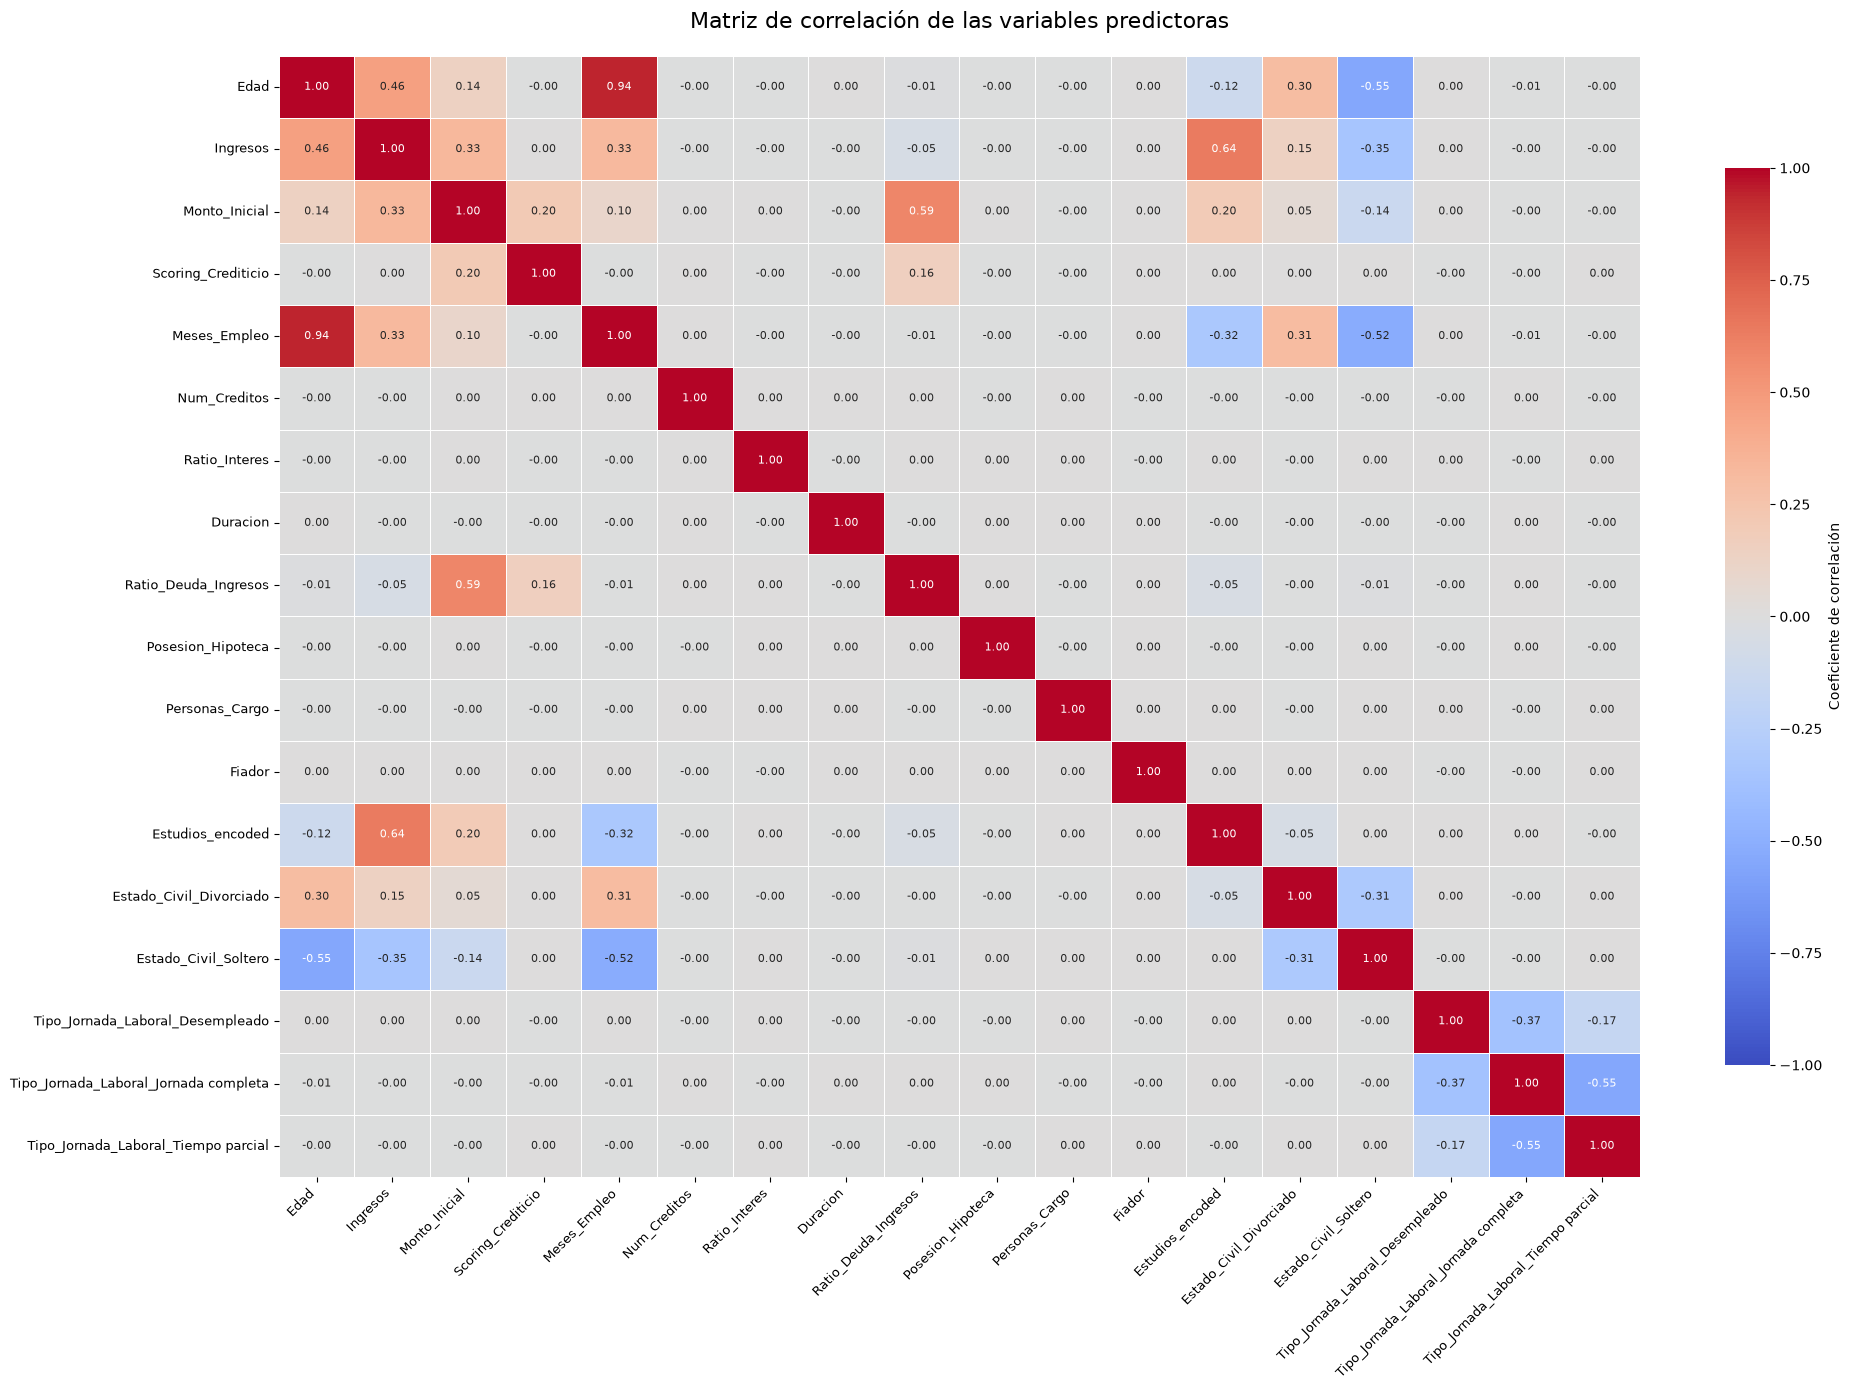

In [15]:
# Matriz de correlación de las variables que realmente entran al modelo
correlacion = X_simple.corr()

plt.figure(figsize=(20, 14))

sns.heatmap(
    correlacion,
    annot=True,          # Mostrar los valores
    fmt=".2f",           # Dos decimales
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    annot_kws={"size": 8},
    cbar_kws={
        "label": "Coeficiente de correlación",
        "shrink": 0.8
    }
)

plt.title(
    "Matriz de correlación de las variables predictoras",
    fontsize=16,
    pad=20
)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=9
)

plt.yticks(
    rotation=0,
    fontsize=9
)

plt.tight_layout()
plt.show()

Las variables 'Edad' y 'Meses_Empleo' están muy correlacionadas, se decide eliminar 'Edad' ya que 'Meses_Empleo' da más información acerca de la vida laboral de cada cliente.

In [16]:
columnas_excluir = [
    "Impago",
    "ID",
    "Prima",
    "Edad"
]

In [17]:
X_simple = df.drop(columns=columnas_excluir)
y_simple = df["Impago"]

In [18]:
# Variables binarias: columnas que solo contienen 0 y 1
cols_binarias_simple = [
    columna for columna in X_simple.columns
    if set(X_simple[columna].dropna().unique()).issubset({0, 1})
]

# Resto de variables numéricas
cols_num_simple = [
    columna for columna in X_simple.columns
    if columna not in cols_binarias_simple
]

print("Variables numéricas:", cols_num_simple)
print("Variables binarias:", cols_binarias_simple)

Variables numéricas: ['Ingresos', 'Monto_Inicial', 'Scoring_Crediticio', 'Meses_Empleo', 'Num_Creditos', 'Ratio_Interes', 'Duracion', 'Ratio_Deuda_Ingresos', 'Estudios_encoded']
Variables binarias: ['Posesion_Hipoteca', 'Personas_Cargo', 'Fiador', 'Estado_Civil_Divorciado', 'Estado_Civil_Soltero', 'Tipo_Jornada_Laboral_Desempleado', 'Tipo_Jornada_Laboral_Jornada completa', 'Tipo_Jornada_Laboral_Tiempo parcial']


Se estandarizan las variables numéricas no binarias, incluidas las variables codificadas mediante ordinal encoding. Las variables binarias se mantienen con valores 0 y 1. El escalador se ajusta exclusivamente con los datos de entrenamiento y posteriormente se aplica al conjunto de prueba y al conjunto completo.

Se utiliza regularización L2 (Ridge) para reducir el riesgo de sobreajuste y controlar la magnitud de los coeficientes. A diferencia de L1, esta regularización no elimina variables, sino que penaliza los coeficientes elevados, lo que resulta apropiado cuando se desea conservar toda la información disponible. Además, proporciona mayor estabilidad cuando existen variables relacionadas entre sí. El valor del hiperparámetro \(C\) se selecciona mediante validación cruzada, utilizando ROC-AUC como métrica de evaluación.

In [19]:
X_train_simple, X_test_simple, y_train_simple, y_test_simple = train_test_split(
    X_simple,
    y_simple,
    train_size=0.8,
    random_state=42,
    shuffle=True,
    stratify=y_simple
)

scaler_simple = StandardScaler()

# Copias para no modificar los conjuntos originales
X_train_scaled_simple = X_train_simple.copy()
X_test_scaled_simple = X_test_simple.copy()

# Ajustar solamente con las variables numéricas de entrenamiento
X_train_scaled_simple[cols_num_simple] = scaler_simple.fit_transform(
    X_train_simple[cols_num_simple]
)

# Aplicar la misma transformación a test
X_test_scaled_simple[cols_num_simple] = scaler_simple.transform(
    X_test_simple[cols_num_simple]
)

In [20]:
# Regresión logística Ridge con búsqueda del mejor C
modelo_cv_l2_simple = LogisticRegressionCV(
    Cs=np.logspace(-4, 4, 50),
    cv=5,
    penalty="l2",
    solver="lbfgs",
    scoring="roc_auc",
    max_iter=5000,
    random_state=42
)

modelo_cv_l2_simple.fit(
    X_train_scaled_simple,
    y_train_simple
)

c:\Users\izaro\RETO5\RETO5\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
c:\Users\izaro\RETO5\RETO5\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
c:\Users\izaro\RETO5\RETO5\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes o

,"Cs Cs: int or list of floats, default=10Each of the values in Cs describes the inverse of regularizationstrength. If Cs is as an int, then a grid of Cs values are chosenin a logarithmic scale between 1e-4 and 1e4.Like in support vector machines, smaller values specify strongerregularization.",array([1.0000...00000000e+04])
,"cv cv: int or cross-validation generator, default=NoneThe default cross-validation generator used is Stratified K-Folds.If an integer is provided, it specifies the number of folds, `n_folds`, used.See the module :mod:`sklearn.model_selection` module for thelist of possible cross-validation objects... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"penalty penalty: {'l1', 'l2', 'elasticnet'}, default='l2'Specify the norm of the penalty:- `'l2'`: add an L2 penalty term (used by default);- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"scoring scoring: str or callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: :ref:`accuracy <accuracy_score>` is used... versionchanged:: 1.11 The default will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11.",'roc_auc'
,"max_iter max_iter: int, default=100Maximum number of iterations of the optimization algorithm.",5000
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.Note that this only applies to the solver and not the cross-validationgenerator. See :term:`Glossary <random_state>` for details.",42
,"l1_ratios l1_ratios: array-like of shape (n_l1_ratios), default=NoneFloats between 0 and 1 passed as Elastic-Net mixing parameter (scaling betweenL1 and L2 penalties). For `l1_ratio = 0` the penalty is an L2 penalty. For`l1_ratio = 1` it is an L1 penalty. For `0 < l1_ratio < 1`, the penalty is acombination of L1 and L2.All the values of the given array-like are tested by cross-validation and theone giving the best prediction score is used... warning:: Certain values of `l1_ratios`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... deprecated:: 1.8 `l1_ratios=None` is deprecated in 1.8 and will raise an error in version 1.10. Default value will change from `None` to `(0.0,)` in version 1.10.",'warn'
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer dual=False whenn_samples > n_features.",False
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'n

In [21]:
mejor_C_l2_simple = modelo_cv_l2_simple.C_[0]

print("Mejor C modelo sencillo:", mejor_C_l2_simple)

Mejor C modelo sencillo: 5.428675439323859


In [22]:
probabilidad_simple = (
    modelo_cv_l2_simple.predict_proba(
        X_test_scaled_simple
    )[:, 1]
)

In [23]:
roc_auc_simple = roc_auc_score(
    y_test_simple,
    probabilidad_simple
)

pr_auc_simple = average_precision_score(
    y_test_simple,
    probabilidad_simple
)

print("ROC-AUC simple:", round(roc_auc_simple, 6))
print("PR-AUC simple:", round(pr_auc_simple, 6))

ROC-AUC simple: 0.687749
PR-AUC simple: 0.223092


# 4. Modelo con variables financieras

In [24]:
X_finan = df_finan.drop(columns=columnas_excluir)
y_finan = df_finan["Impago"]

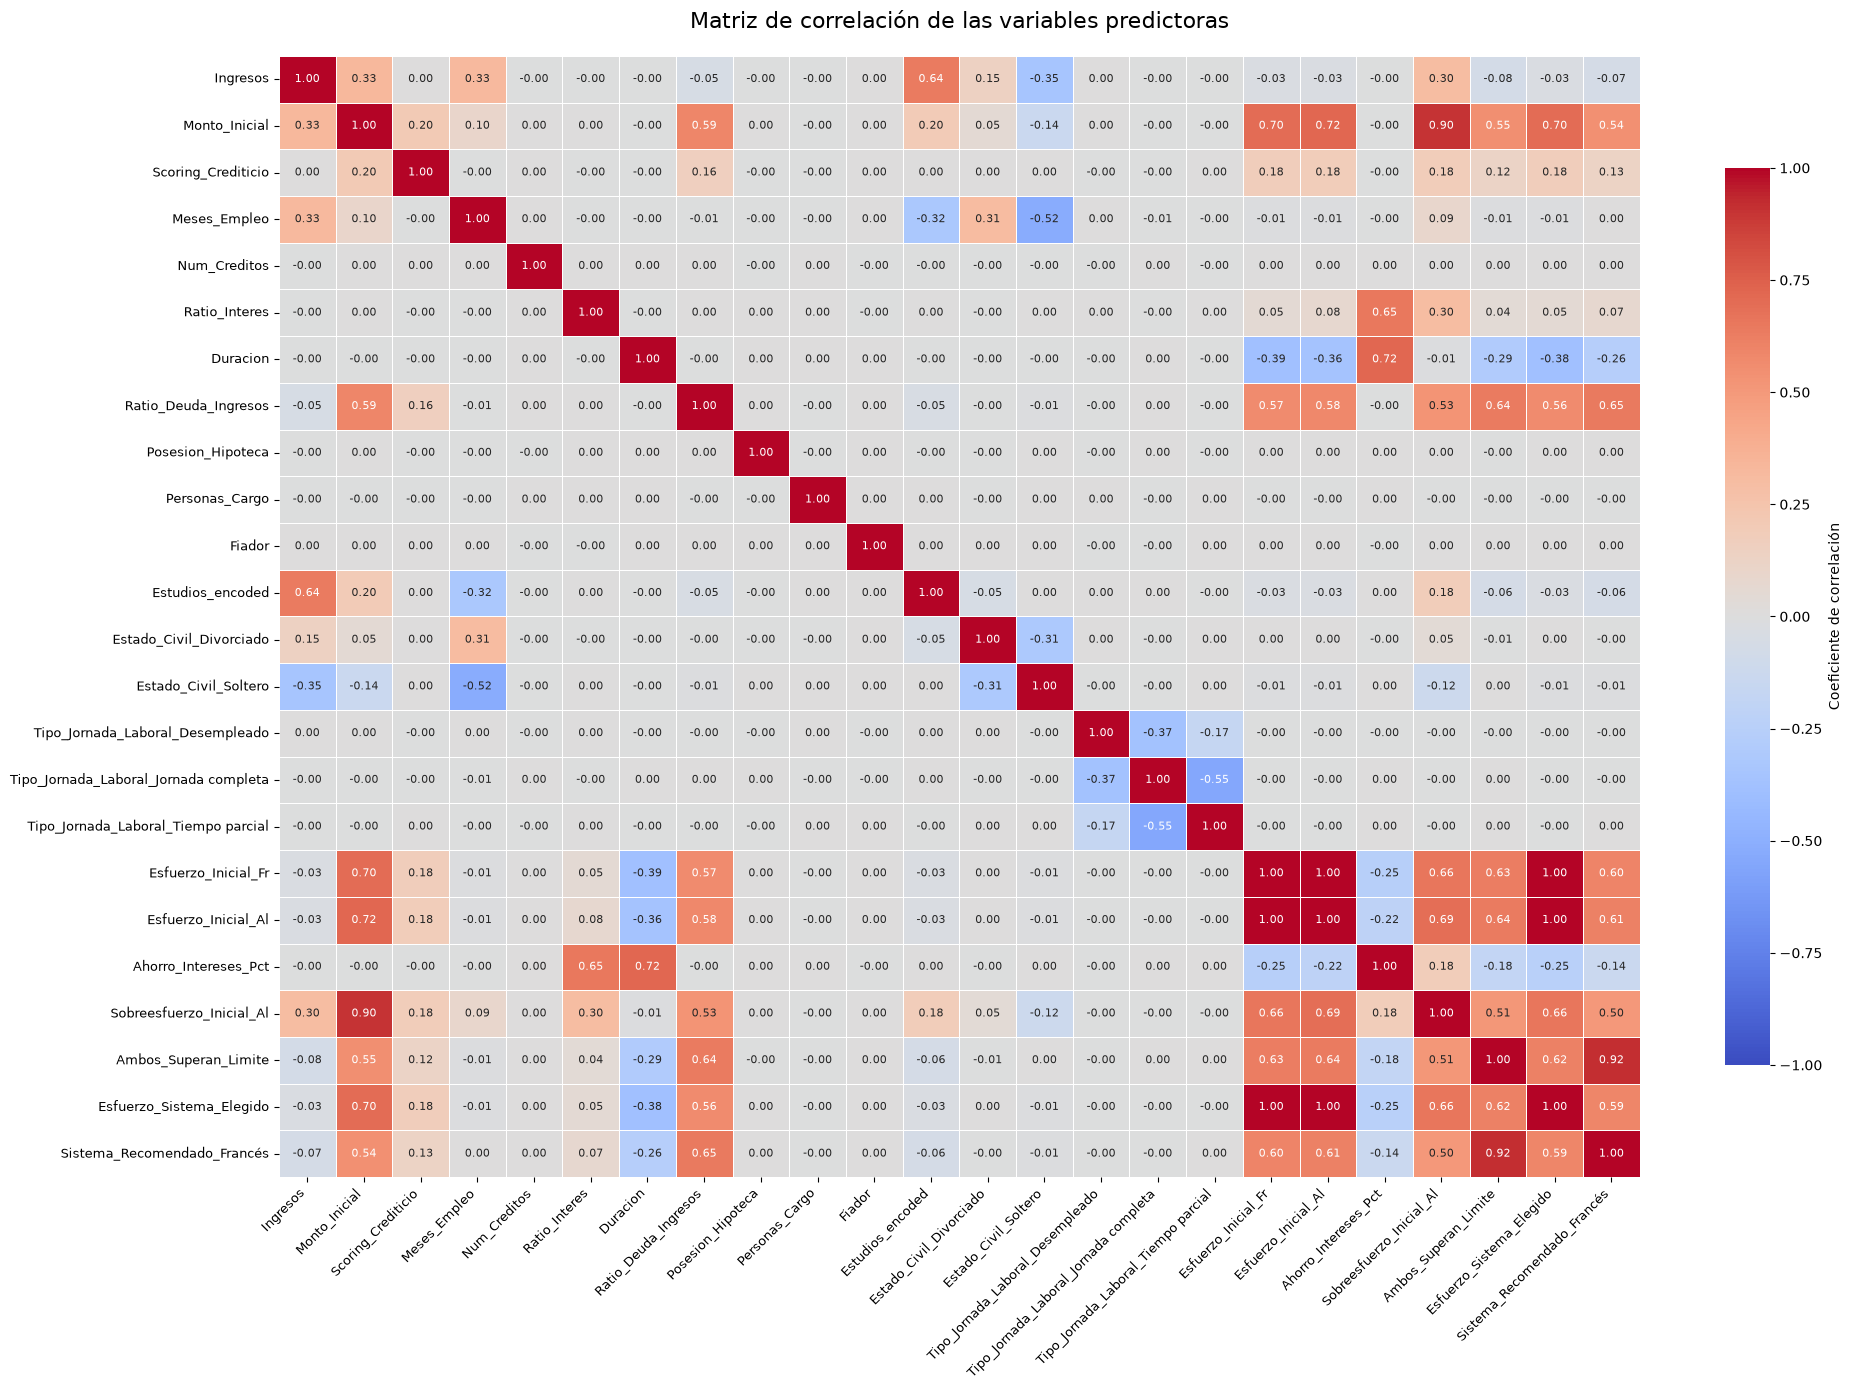

In [25]:
# Matriz de correlación de las variables que realmente entran al modelo
correlacion = X_finan.corr()

plt.figure(figsize=(20, 14))

sns.heatmap(
    correlacion,
    annot=True,          # Mostrar los valores
    fmt=".2f",           # Dos decimales
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    annot_kws={"size": 8},
    cbar_kws={
        "label": "Coeficiente de correlación",
        "shrink": 0.8
    }
)

plt.title(
    "Matriz de correlación de las variables predictoras",
    fontsize=16,
    pad=20
)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=9
)

plt.yticks(
    rotation=0,
    fontsize=9
)

plt.tight_layout()
plt.show()

In [26]:
columnas_excluir = [
    "Impago",
    "ID",
    "Prima",
    "Esfuerzo_Inicial_Fr",
    "Esfuerzo_Inicial_Al",
    "Edad",
    "Sobreesfuerzo_Inicial_Al",
    "Ambos_Superan_Limite"
]

X_finan = df_finan.drop(columns=columnas_excluir)
y_finan = df_finan["Impago"]

Se eliminaron las variables con correlaciones superiores a 0,90 para reducir la multicolinealidad. Se mantuvo Meses_Empleo frente a Edad por su mayor interpretación crediticia, Monto_Inicial frente a Sobreesfuerzo_Inicial_Al por ser una variable original, y Sistema_Recomendado_Francés frente a Ambos_Superan_Limite para conservar explícitamente el sistema de amortización asignado.

In [27]:
# Variables binarias: columnas que solo contienen 0 y 1
cols_binarias = [
    columna for columna in X_finan.columns
    if set(X_finan[columna].dropna().unique()).issubset({0, 1})
]

# Resto de variables numéricas
cols_num = [
    columna for columna in X_finan.columns
    if columna not in cols_binarias
]

print("Variables numéricas:", cols_num)
print("Variables binarias:", cols_binarias)

Variables numéricas: ['Ingresos', 'Monto_Inicial', 'Scoring_Crediticio', 'Meses_Empleo', 'Num_Creditos', 'Ratio_Interes', 'Duracion', 'Ratio_Deuda_Ingresos', 'Estudios_encoded', 'Ahorro_Intereses_Pct', 'Esfuerzo_Sistema_Elegido']
Variables binarias: ['Posesion_Hipoteca', 'Personas_Cargo', 'Fiador', 'Estado_Civil_Divorciado', 'Estado_Civil_Soltero', 'Tipo_Jornada_Laboral_Desempleado', 'Tipo_Jornada_Laboral_Jornada completa', 'Tipo_Jornada_Laboral_Tiempo parcial', 'Sistema_Recomendado_Francés']


Se estandarizan las variables numéricas no binarias, incluidas las variables codificadas mediante ordinal encoding. Las variables binarias se mantienen con valores 0 y 1. El escalador se ajusta exclusivamente con los datos de entrenamiento y posteriormente se aplica al conjunto de prueba y al conjunto completo.

In [28]:
X_train_finan, X_test_finan, y_train_finan, y_test_finan = train_test_split(
    X_finan,
    y_finan,
    train_size=0.8,
    random_state=42,
    shuffle=True,
    stratify=y_finan
)

scaler_finan = StandardScaler()

# Copias para no modificar los conjuntos originales
X_train_scaled_finan = X_train_finan.copy()
X_test_scaled_finan = X_test_finan.copy()

# Ajustar solamente con las variables numéricas de entrenamiento
X_train_scaled_finan[cols_num] = scaler_finan.fit_transform(
    X_train_finan[cols_num]
)

# Aplicar la misma transformación a test
X_test_scaled_finan[cols_num] = scaler_finan.transform(
    X_test_finan[cols_num]
)

Se utiliza regularización L2 (Ridge) para reducir el riesgo de sobreajuste y controlar la magnitud de los coeficientes. A diferencia de L1, esta regularización no elimina variables, sino que penaliza los coeficientes elevados, lo que resulta apropiado cuando se desea conservar toda la información disponible. Además, proporciona mayor estabilidad cuando existen variables relacionadas entre sí. El valor del hiperparámetro \(C\) se selecciona mediante validación cruzada, utilizando ROC-AUC como métrica de evaluación.

Para seleccionar la intensidad de regularización se realiza una búsqueda del hiperparámetro C mediante validación cruzada. 

Para cada valor de C, el conjunto de entrenamiento se divide en cinco particiones. El modelo se entrena con cuatro de ellas y se valida con la restante, repitiendo el proceso cinco veces. Finalmente, se selecciona el valor de C que obtiene el mejor ROC-AUC medio.

In [29]:
modelo_cv_l2 = LogisticRegressionCV(
    Cs=np.logspace(-4, 4, 50),
    cv=5,
    penalty="l2",
    solver="lbfgs",
    scoring="roc_auc",
    max_iter=5000,
    random_state=42
)

In [30]:
modelo_cv_l2.fit(
    X_train_scaled_finan,
    y_train_finan
)

c:\Users\izaro\RETO5\RETO5\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
c:\Users\izaro\RETO5\RETO5\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
c:\Users\izaro\RETO5\RETO5\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes o

,"Cs Cs: int or list of floats, default=10Each of the values in Cs describes the inverse of regularizationstrength. If Cs is as an int, then a grid of Cs values are chosenin a logarithmic scale between 1e-4 and 1e4.Like in support vector machines, smaller values specify strongerregularization.",array([1.0000...00000000e+04])
,"cv cv: int or cross-validation generator, default=NoneThe default cross-validation generator used is Stratified K-Folds.If an integer is provided, it specifies the number of folds, `n_folds`, used.See the module :mod:`sklearn.model_selection` module for thelist of possible cross-validation objects... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"penalty penalty: {'l1', 'l2', 'elasticnet'}, default='l2'Specify the norm of the penalty:- `'l2'`: add an L2 penalty term (used by default);- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"scoring scoring: str or callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: :ref:`accuracy <accuracy_score>` is used... versionchanged:: 1.11 The default will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11.",'roc_auc'
,"max_iter max_iter: int, default=100Maximum number of iterations of the optimization algorithm.",5000
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.Note that this only applies to the solver and not the cross-validationgenerator. See :term:`Glossary <random_state>` for details.",42
,"l1_ratios l1_ratios: array-like of shape (n_l1_ratios), default=NoneFloats between 0 and 1 passed as Elastic-Net mixing parameter (scaling betweenL1 and L2 penalties). For `l1_ratio = 0` the penalty is an L2 penalty. For`l1_ratio = 1` it is an L1 penalty. For `0 < l1_ratio < 1`, the penalty is acombination of L1 and L2.All the values of the given array-like are tested by cross-validation and theone giving the best prediction score is used... warning:: Certain values of `l1_ratios`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... deprecated:: 1.8 `l1_ratios=None` is deprecated in 1.8 and will raise an error in version 1.10. Default value will change from `None` to `(0.0,)` in version 1.10.",'warn'
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer dual=False whenn_samples > n_features.",False
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'n

In [31]:
mejor_C_l2 = modelo_cv_l2.C_[0]

print(
    "Mejor C con regularización L2:",
    mejor_C_l2
)

Mejor C con regularización L2: 0.3906939937054613


In [32]:
probabilidad_l2 = modelo_cv_l2.predict_proba(
    X_test_scaled_finan
)[:, 1]

In [33]:
roc_auc_l2 = roc_auc_score(
    y_test_finan,
    probabilidad_l2
)

pr_auc_l2 = average_precision_score(
    y_test_finan,
    probabilidad_l2
)

print("ROC-AUC L2:", round(roc_auc_l2, 3))
print("PR-AUC L2:", round(pr_auc_l2, 3))

ROC-AUC L2: 0.688
PR-AUC L2: 0.223


# 5. Comparación de modelos

In [34]:
comparacion_modelos = pd.DataFrame({
    "Modelo": [
        "Modelo simple",
        "Modelo con variables financieras"
    ],
    "ROC-AUC": [
        roc_auc_simple,
        roc_auc_l2
    ],
    "PR-AUC": [
        pr_auc_simple,
        pr_auc_l2
    ],
    "Número de variables": [
        X_simple.shape[1],
        X_finan.shape[1]
    ]
})

comparacion_modelos

,Modelo,ROC-AUC,PR-AUC,Número de variables
0,Modelo simple,0.687749,0.223092,17
1,Modelo con variables financieras,0.687668,0.223259,20


Los dos modelos presentan un rendimiento predictivo prácticamente idéntico. El modelo simple obtiene un ROC-AUC de 0,687749, ligeramente superior al 0,687668 obtenido por el modelo con variables financieras. Por su parte, el modelo financiero presenta una mejora mínima en PR-AUC, de 0,223092 a 0,223259. Estas diferencias son tan reducidas que no pueden considerarse relevantes desde el punto de vista práctico.

Por tanto, siguiendo el principio de parsimonia, se selecciona el modelo simple con regularización L2. Este modelo utiliza 17 variables frente a las 20 del modelo financiero, requiere menos transformaciones y obtiene una capacidad predictiva equivalente. Las variables financieras calculadas no aportan una mejora suficiente que justifique aumentar la complejidad del modelo.

# 6. Modelo final

Tras comparar ambos modelos, se selecciona el modelo simple con regularización L2, ya que presenta una capacidad predictiva equivalente utilizando un menor número de variables. El modelo final se mantiene ajustado sobre el conjunto de entrenamiento y conserva el conjunto de prueba como referencia independiente de su capacidad predictiva. Posteriormente, se utiliza para estimar la probabilidad de impago de todas las observaciones del dataset.

In [35]:
modelo_final = modelo_cv_l2_simple

In [36]:
X_total_simple_scaled = X_simple.copy()

X_total_simple_scaled[cols_num_simple] = scaler_simple.transform(
    X_simple[cols_num_simple]
)

In [37]:
probabilidad_impago = modelo_final.predict_proba(
    X_total_simple_scaled
)[:, 1]

In [38]:
df_resultado = df.copy()

df_resultado["Probabilidad_Impago"] = probabilidad_impago

Las probabilidades correspondientes a las observaciones de entrenamiento son estimaciones dentro de muestra, mientras que las del conjunto de prueba proceden de observaciones no utilizadas durante el ajuste.

# 7. Interpretación de los coeficientes y análisis estadístico con statsmodels

In [39]:
coeficientes_finales = pd.DataFrame({
    "Variable": X_simple.columns,
    "Coeficiente": modelo_final.coef_[0],
    "Odds_ratio": np.exp(modelo_final.coef_[0])
})

coeficientes_finales = coeficientes_finales.sort_values(
    by="Coeficiente",
    ascending=False
)

print("Intercepto:", modelo_final.intercept_[0])

coeficientes_finales

Intercepto: -2.2364446472846007


,Variable,Coeficiente,Odds_ratio
5,Ratio_Interes,0.408768,1.504962
13,Estado_Civil_Soltero,0.043529,1.044490
16,Tipo_Jornada_Laboral_Tiempo parcial,0.020371,1.020580
15,Tipo_Jornada_Laboral_Jornada completa,0.017048,1.017195
12,Estado_Civil_Divorciado,0.009853,1.009902
14,Tipo_Jornada_Laboral_Desempleado,0.007994,1.008026
9,Personas_Cargo,0.004317,1.004327
7,Ratio_Deuda_Ingresos,0.004093,1.004102
0,Ingresos,0.002586,1.002589
4,Num_Creditos,-0.001812,0.998190


Cómo interpretar los coeficientes
- Coeficiente positivo: la variable está relacionada con una mayor probabilidad de impago.
- Coeficiente negativo: está relacionada con una menor probabilidad de impago.
- Coeficiente próximo a cero: su influencia es reducida, manteniendo constantes las demás variables.
- Odds_ratio > 1: aumentan las odds de impago.
- Odds_ratio < 1: disminuyen las odds de impago.
- Odds_ratio = 1: prácticamente no existe efecto.

In [40]:
coeficientes_finales["Coeficiente_absoluto"] = (
    coeficientes_finales["Coeficiente"].abs()
)

coeficientes_finales.sort_values(
    by="Coeficiente_absoluto",
    ascending=False
).head(17)

,Variable,Coeficiente,Odds_ratio,Coeficiente_absoluto
3,Meses_Empleo,-0.571933,0.564433,0.571933
5,Ratio_Interes,0.408768,1.504962,0.408768
2,Scoring_Crediticio,-0.101519,0.903464,0.101519
11,Estudios_encoded,-0.075857,0.926948,0.075857
1,Monto_Inicial,-0.063363,0.938603,0.063363
13,Estado_Civil_Soltero,0.043529,1.044490,0.043529
16,Tipo_Jornada_Laboral_Tiempo parcial,0.020371,1.020580,0.020371
8,Posesion_Hipoteca,-0.020323,0.979883,0.020323
15,Tipo_Jornada_Laboral_Jornada completa,0.017048,1.017195,0.017048
12,Estado_Civil_Divorciado,0.009853,1.009902,0.009853


Para complementar la interpretación del modelo se ajusta una regresión logística mediante statsmodels, utilizando las mismas observaciones de entrenamiento y las mismas variables transformadas. Este análisis permite obtener p-valores e intervalos de confianza. No obstante, se trata de un modelo sin regularización L2, por lo que sus coeficientes pueden diferir ligeramente de los del modelo predictivo final. Las probabilidades finales se obtienen exclusivamente con el modelo regularizado de scikit-learn.

In [41]:
X_train_stats = sm.add_constant(
    X_train_scaled_simple,
    prepend=True
)

In [42]:
modelo_stats = sm.Logit(
    endog=y_train_simple.astype(float),
    exog=X_train_stats.astype(float)
)

resultado_stats = modelo_stats.fit()

print(resultado_stats.summary())

Optimization terminated successfully.
         Current function value: 0.335955
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                 Impago   No. Observations:               142884
Model:                          Logit   Df Residuals:                   142866
Method:                           MLE   Df Model:                           17
Date:                Sat, 24 Oct 2026   Pseudo R-squ.:                 0.06552
Time:                        18:38:32   Log-Likelihood:                -48003.
converged:                       True   LL-Null:                       -51368.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                            coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------
const                                    -2.2412      

El modelo presenta un LLR p-value inferior a 0,05, por lo que se rechaza la hipótesis nula de que todos los coeficientes sean simultáneamente iguales a cero. Por tanto, el conjunto de variables aporta información estadísticamente significativa para explicar el impago. El pseudo R^2 de McFadden es 0,0655. Este indicador no debe interpretarse como el R^2 de una regresión lineal, por lo que la capacidad predictiva del modelo se evalúa principalmente mediante ROC-AUC y PR-AUC.

El análisis estadístico muestra que el modelo es globalmente significativo, dado que el LLR p-value es inferior a 0,05. Las variables con una relación individual estadísticamente significativa con el impago son el monto inicial, el scoring crediticio, los meses de empleo, el ratio de interés y el nivel de estudios. El ratio de interés presenta una relación positiva con el riesgo de impago, mientras que el scoring crediticio, la estabilidad laboral, el monto inicial y el nivel de estudios presentan una relación negativa. Los meses de empleo y el ratio de interés son las variables con coeficientes de mayor magnitud.

El resto de las variables no presenta significación estadística individual al nivel del 5 %, una vez controlado el efecto de las demás. No obstante, se mantienen en el modelo predictivo debido al uso de regularización L2 y porque la selección del modelo se ha basado en su capacidad predictiva conjunta, evaluada mediante ROC-AUC y PR-AUC. El análisis de statsmodels tiene una finalidad explicativa y complementaria, mientras que las probabilidades finales se obtienen con el modelo regularizado de scikit-learn.

Comprobamos las probabilidades generadas

In [43]:
df_resultado[
    ["ID", "Impago", "Probabilidad_Impago"]
].head()

,ID,Impago,Probabilidad_Impago
0,KG9CT9,0,0.175035
1,V5O0K9,0,0.080365
2,YE5GD0,0,0.102163
3,Q6HQ3D,0,0.087424
4,XO8CO4,0,0.150840


In [44]:
print(
    df_resultado["Probabilidad_Impago"].describe()
)

print(
    "Valores ausentes:",
    df_resultado["Probabilidad_Impago"].isna().sum()
)

print(
    "Probabilidad mínima:",
    df_resultado["Probabilidad_Impago"].min()
)

print(
    "Probabilidad máxima:",
    df_resultado["Probabilidad_Impago"].max()
)

count    178606.000000
mean          0.116330
std           0.071837
min           0.009456
25%           0.061127
50%           0.098858
75%           0.155539
max           0.550159
Name: Probabilidad_Impago, dtype: float64
Valores ausentes: 0
Probabilidad mínima: 0.0094558015230223
Probabilidad máxima: 0.5501591361288128


# 8. Exportación de resultados

Finalmente, se incorpora la probabilidad estimada de impago al dataset original y se exporta el resultado para utilizar esta variable en el posterior modelo de estimación de la prima.

In [45]:
df_resultado.to_csv(
    "data/datos_con_probabilidad_impago.csv",
    index=False
)